# DWM Lab 4 — Simple and Multiple Linear Regression

### Dataset: Online Retail

**Objective:**  
To implement **Simple Linear Regression** and **Multiple Linear Regression** on the Online Retail dataset and evaluate the models using **R² Score** and **Mean Squared Error (MSE)**.

### Adaptation from the original lab

The original experiment uses a `Retail_Sales.csv` dataset containing **Advertising, Discount, Store Size and Sales**.  
The selected Online Retail dataset does not contain those columns, so the same regression concepts are applied using equivalent numerical retail variables:

- **Quantity** → independent variable for Simple Linear Regression
- **Quantity, UnitPrice, Month** → independent variables for Multiple Linear Regression
- **SalesAmount = Quantity × UnitPrice** → dependent variable (Sales)

This keeps the experiment focused on the same regression techniques while using one common dataset for all DWM labs.

## 1. Import Required Libraries

Import Pandas for data handling, Matplotlib for visualization, and Scikit-learn for train-test splitting, linear regression and evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## 2. Load the Dataset

Load the `Online Retail.xlsx` file into a Pandas DataFrame.

In [2]:
file_path = "Online Retail.xlsx"
data = pd.read_excel(file_path)

print("Dataset:")
display(data.head())

print("Shape:", data.shape)

Dataset:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Shape: (541909, 8)


## 3. Data Preprocessing

For regression, we use valid sales transactions only.

Steps:
1. Convert `InvoiceDate` to datetime.
2. Remove cancelled invoices.
3. Remove transactions with non-positive quantity or unit price.
4. Create `SalesAmount = Quantity × UnitPrice`.
5. Extract the month from `InvoiceDate`.
6. Remove rows with missing values in the variables required for regression.

In [3]:
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])

# Remove cancelled invoices
data = data[~data['InvoiceNo'].astype(str).str.startswith('C')].copy()

# Keep valid transactions
data = data[
    (data['Quantity'] > 0) &
    (data['UnitPrice'] > 0)
].copy()

# Create dependent variable
data['SalesAmount'] = data['Quantity'] * data['UnitPrice']

# Extract month
data['Month'] = data['InvoiceDate'].dt.month

# Keep only required columns and remove missing values
data = data[['Quantity', 'UnitPrice', 'Month', 'SalesAmount']].dropna()

print("Cleaned dataset shape:", data.shape)
display(data.head())

Cleaned dataset shape: (530104, 4)


,Quantity,UnitPrice,Month,SalesAmount
0,6,2.55,12,15.30
1,6,3.39,12,20.34
2,8,2.75,12,22.00
3,6,3.39,12,20.34
4,6,3.39,12,20.34


## 4. Simple Linear Regression

### Predict Sales Amount using Quantity

Simple Linear Regression uses one independent variable (`Quantity`) to predict one dependent variable (`SalesAmount`).

The model is represented as:

**Y = b₀ + b₁X**

where:
- `Y` = predicted Sales Amount
- `X` = Quantity
- `b₀` = intercept
- `b₁` = regression coefficient

In [4]:
# Independent and dependent variables
X = data[['Quantity']]
y = data['SalesAmount']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
slr = LinearRegression()
slr.fit(X_train, y_train)

# Predict
y_pred = slr.predict(X_test)

print("Simple Linear Regression")
print("------------------------")
print("Intercept:", slr.intercept_)
print("Coefficient:", slr.coef_[0])

print("\nFirst 10 Actual Sales:", list(y_test.head(10)))
print("First 10 Predicted Sales:", list(y_pred[:10]))

print("\nR2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

Simple Linear Regression
------------------------
Intercept: 3.429477218074595
Coefficient: 1.5825038757632028

First 10 Actual Sales: [15.9, 17.0, 12.450000000000001, 0.65, 5.1, 2.9, 8.5, 2.1, 4.9799999999999995, 13.5]
First 10 Predicted Sales: [np.float64(6.594484969601001), np.float64(9.759492721127407), np.float64(8.176988845364203), np.float64(5.011981093837798), np.float64(12.924500472653811), np.float64(6.594484969601001), np.float64(19.254515975706624), np.float64(5.011981093837798), np.float64(8.176988845364203), np.float64(6.594484969601001)]

R2 Score: 0.09491385995551704
Mean Squared Error: 17549.02624252553


## 5. Plot Simple Linear Regression

Plot the actual observations and the fitted regression line.

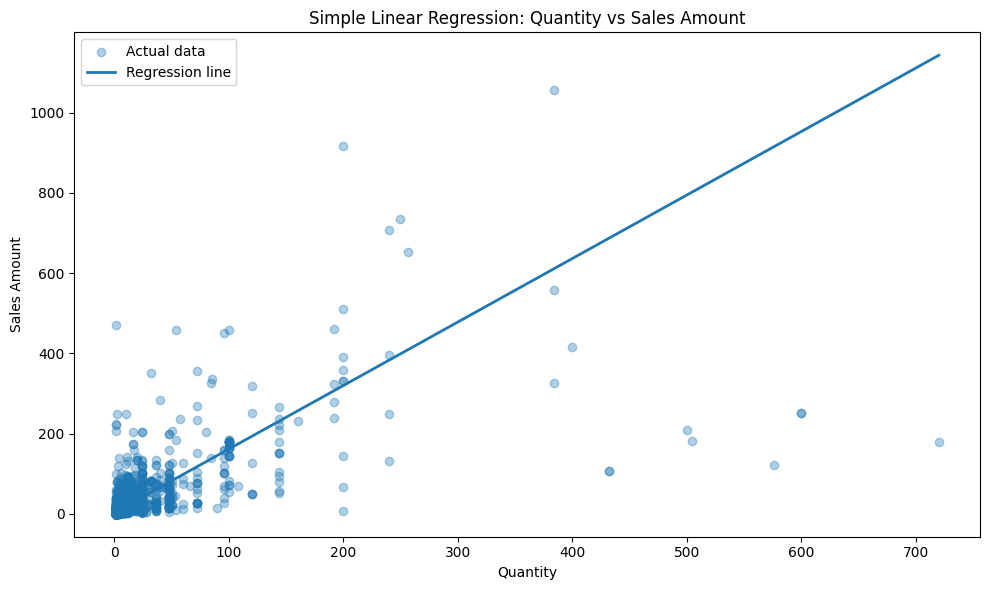

In [5]:
# Use a sample for clearer visualization because the dataset is large
plot_data = data.sample(min(5000, len(data)), random_state=42).sort_values('Quantity')

X_plot = plot_data[['Quantity']]
y_plot_pred = slr.predict(X_plot)

plt.figure(figsize=(10, 6))
plt.scatter(
    plot_data['Quantity'],
    plot_data['SalesAmount'],
    alpha=0.35,
    label='Actual data'
)
plt.plot(
    plot_data['Quantity'],
    y_plot_pred,
    linewidth=2,
    label='Regression line'
)

plt.title('Simple Linear Regression: Quantity vs Sales Amount')
plt.xlabel('Quantity')
plt.ylabel('Sales Amount')
plt.legend()
plt.tight_layout()
plt.show()

## 6. Multiple Linear Regression

### Predict Sales Amount using Quantity, Unit Price and Month

Multiple Linear Regression uses more than one independent variable.

The model is represented as:

**Y = b₀ + b₁X₁ + b₂X₂ + ... + bₙXₙ**

Here:
- `Y` = Sales Amount
- `X₁` = Quantity
- `X₂` = Unit Price
- `X₃` = Month

In [6]:
# Select input features
X = data[['Quantity', 'UnitPrice', 'Month']]

# Select target variable
y = data['SalesAmount']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Multiple Linear Regression model
mlr = LinearRegression()

# Train the model
mlr.fit(X_train, y_train)

# Predict
y_pred = mlr.predict(X_test)

print("Multiple Linear Regression")
print("--------------------------")
print("Intercept:", mlr.intercept_)

print("\nCoefficients:")
for feature, coef in zip(X.columns, mlr.coef_):
    print(feature, ":", coef)

print("\nFirst 10 Actual Sales:", list(y_test.head(10)))
print("First 10 Predicted Sales:", list(y_pred[:10]))

print("\nR2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

Multiple Linear Regression
--------------------------
Intercept: -2.2560532365847266

Coefficients:
Quantity : 1.5832498189921043
UnitPrice : 1.0204840687098822
Month : 0.21912047930666045

First 10 Actual Sales: [15.9, 17.0, 12.450000000000001, 0.65, 5.1, 2.9, 8.5, 2.1, 4.9799999999999995, 13.5]
First 10 Predicted Sales: [np.float64(10.557138102789668), np.float64(8.85224429001401), np.float64(9.358150857217524), np.float64(0.20963170637546158), np.float64(10.302061928837905), np.float64(3.923991656175434), np.float64(15.101217849659697), np.float64(3.6614179197647347), np.float64(6.8171455261299165), np.float64(9.989918658257789)]

R2 Score: 0.14351073556698046
Mean Squared Error: 16606.76471881199


## 7. Predict Sales for a New Transaction

Use the trained Multiple Linear Regression model to predict the sales amount for a new transaction.

Example:
- Quantity = 10
- Unit Price = 5
- Month = 12

In [7]:
new_data = pd.DataFrame({
    'Quantity': [10],
    'UnitPrice': [5],
    'Month': [12]
})

prediction = mlr.predict(new_data)

print("New Transaction:")
display(new_data)

print("Predicted Sales Amount =", prediction[0])

New Transaction:


,Quantity,UnitPrice,Month
0,10,5,12


Predicted Sales Amount = 21.308311048565653


## 8. Compare the Regression Models

Compare the R² Score and MSE of Simple Linear Regression and Multiple Linear Regression.

In [8]:
# Recalculate SLR metrics for comparison
slr_r2 = r2_score(
    y_test if False else data.loc[X_test.index, 'SalesAmount'],
    slr.predict(data.loc[X_test.index, ['Quantity']])
)

# Use the actual MLR test metrics
mlr_r2 = r2_score(y_test, y_pred)
mlr_mse = mean_squared_error(y_test, y_pred)

# Create a fresh SLR split with the same indices for a clean comparison
comparison_X = data[['Quantity']]
comparison_y = data['SalesAmount']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    comparison_X, comparison_y, test_size=0.2, random_state=42
)

slr_compare = LinearRegression()
slr_compare.fit(X_train_s, y_train_s)
slr_pred = slr_compare.predict(X_test_s)

slr_r2 = r2_score(y_test_s, slr_pred)
slr_mse = mean_squared_error(y_test_s, slr_pred)

comparison = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'R2 Score': [slr_r2, mlr_r2],
    'Mean Squared Error': [slr_mse, mlr_mse]
})

display(comparison)

,Model,R2 Score,Mean Squared Error
0,Simple Linear Regression,0.094914,17549.026243
1,Multiple Linear Regression,0.143511,16606.764719


## Conclusion

Simple Linear Regression was implemented using **Quantity** to predict **Sales Amount**.

Multiple Linear Regression was implemented using **Quantity, Unit Price and Month** to predict **Sales Amount**.

Both models were evaluated using:
- **R² Score**
- **Mean Squared Error (MSE)**

The same Online Retail dataset can now be reused for the remaining DWM experiments.